# 02 · Baselines y modelo estadístico

**Objetivo:** fijar el nivel de referencia que tendrán que superar los modelos de aprendizaje automático (LightGBM y la red neuronal). Un modelo complejo solo se justifica si le gana a métodos simples, que además suelen ser muy competitivos en demanda minorista.

**Modelos de este notebook** (todos pronostican 28 días desde un origen, usando solo datos anteriores a él):

| Modelo | Qué hace |
|---|---|
| **Cero** | Pronostica siempre 0. No es un modelo serio: sirve para ver cómo se comportan las métricas con demanda intermitente. |
| **Ingenuo** | Repite la última venta observada. |
| **Ingenuo estacional** | Repite lo vendido el mismo día de la semana anterior. |
| **Media móvil de 28 días** | Promedio de los últimos 28 días, igual para todo el horizonte. |
| **Promedio estacional (4 semanas)** | Para cada día, promedia lo vendido ese mismo día de la semana en las últimas 4 semanas. |
| **SES + índice semanal** (modelo estadístico) | Quita la estacionalidad semanal, estima el nivel de la serie con suavizado exponencial simple y le vuelve a poner la estacionalidad. |

**Evaluación:** según el protocolo del notebook 01, en las dos últimas ventanas de 28 días, con RMSSE y MAE. Ninguno de estos modelos tiene hiperparámetros que se ajusten con las ventanas de evaluación (los parámetros se fijaron de antemano o se estiman solo con datos anteriores al origen), por lo que se pueden evaluar en ambas ventanas.

## 1. Setup y datos

In [1]:
import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = os.path.abspath("..")
sys.path.insert(0, ROOT)

from src.data import ensure_m5, load_calendar, load_sales, day_columns, sample_series, SEED
from src.metrics import rmsse, evaluar
from src.forecasting import (
    ventanas, clasificar_demanda, pronostico_cero, pronostico_ingenuo,
    pronostico_ingenuo_estacional, pronostico_media_movil,
    pronostico_promedio_estacional, ses_semanal, guardar_resultados,
)

plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 30)

In [2]:
carpeta = ensure_m5()
calendario = load_calendar(carpeta)
ventas = load_sales(carpeta)
dias = day_columns(ventas)

muestra = sample_series(ventas, n_per_store=60, seed=SEED)
Y = muestra[dias].to_numpy().astype(float)
T = Y.shape[1]
categorias = muestra["cat_id"].astype(str).to_numpy()

# Día de la semana de cada día del calendario (0 = sábado, que es el primer día de los datos)
wday = calendario["wday"].to_numpy() - 1

H = 28
V = ventanas(T, H)
print("Series de la muestra:", Y.shape[0], "| días:", T)
for nombre, (ini, fin) in V.items():
    print(f"{nombre:>10}: días {ini} a {fin} | origen en el día {ini - 1}")

Series de la muestra: 600 | días: 1941
validación: días 1886 a 1913 | origen en el día 1885
      test: días 1914 a 1941 | origen en el día 1913


### 1.1 Eventos dentro de las ventanas de evaluación

Los eventos pueden alterar las ventas, y estos modelos simples no los usan. Se listan los que caen dentro de cada ventana para saber cuánto pueden afectar las métricas.

In [3]:
for nombre, (ini, fin) in V.items():
    ev = calendario.iloc[ini - 1:fin]
    ev = ev[ev["event_name_1"].notna()][["date", "event_name_1", "event_type_1"]]
    print(f"{nombre} ({calendario['date'].iloc[ini - 1].date()} a {calendario['date'].iloc[fin - 1].date()}):")
    print(ev.to_string(index=False) if len(ev) else "  sin eventos")
    print()

validación (2016-03-28 a 2016-04-24):
  sin eventos

test (2016-04-25 a 2016-05-22):
      date   event_name_1 event_type_1
2016-04-30     Pesach End    Religious
2016-05-01 OrthodoxEaster    Religious
2016-05-05  Cinco De Mayo     Cultural
2016-05-08   Mother's day     Cultural



## 2. Pronósticos

Para cada ventana se toma el historial hasta el origen, se pronostican los 28 días siguientes y se comparan con las ventas reales.

**Modelo estadístico (SES + índice semanal).** Dos pasos simples:
1. **Índice semanal:** cuánto más o menos se vende cada día de la semana respecto del promedio, estimado en el último año, por categoría y contando cada serie desde su primera venta. Se estima con todas las series de la categoría juntas, porque una serie con pocas ventas daría un patrón semanal muy ruidoso.
2. **Suavizado exponencial simple:** sobre la serie dividida por el índice semanal, el nivel se actualiza cada día corrigiendo una fracción `alpha` del error: con `alpha` alto se olvida rápido el pasado y con `alpha` bajo el nivel es más estable. Alpha se elige por serie entre cinco valores (0,02 a 0,4), el que mejor predijo los últimos 364 días **anteriores al origen**.

El pronóstico de cada día es el nivel final multiplicado por el índice de ese día de la semana.

In [4]:
def contexto(origen):
    return {"wday_train": wday[:origen], "wday_futuro": wday[origen:origen + H], "grupos": categorias}

MODELOS = {
    "Cero": lambda Y_, c: pronostico_cero(Y_, H),
    "Ingenuo": lambda Y_, c: pronostico_ingenuo(Y_, H),
    "Ingenuo estacional": lambda Y_, c: pronostico_ingenuo_estacional(Y_, H),
    "Media móvil 28 días": lambda Y_, c: pronostico_media_movil(Y_, H),
    "Promedio estacional (4 semanas)": lambda Y_, c: pronostico_promedio_estacional(Y_, H),
    "SES + índice semanal": lambda Y_, c: ses_semanal(Y_, H, c["wday_train"], c["wday_futuro"], c["grupos"])[0],
}

entrenamiento, real, ctxs = {}, {}, {}
for nombre, (ini, fin) in V.items():
    origen = ini - 1
    entrenamiento[nombre] = Y[:, :origen]
    real[nombre] = Y[:, origen:fin]
    ctxs[nombre] = contexto(origen)

preds = {(m, v): f(entrenamiento[v], ctxs[v]) for m, f in MODELOS.items() for v in V}
print("Pronósticos calculados:", len(preds))

Pronósticos calculados: 12


## 3. Resultados

RMSSE (error escalado, promedio simple entre series) y MAE (unidades por serie y día). **Menor es mejor** en ambos. Las series sin ventas antes del origen no tienen escala y quedan fuera del RMSSE; el MAE incluye todas las series.

In [5]:
filas = [{"modelo": m, "ventana": v, **evaluar(entrenamiento[v], real[v], p)} for (m, v), p in preds.items()]
resultados = pd.DataFrame(filas)

tabla = resultados.pivot(index="modelo", columns="ventana", values=["RMSSE", "MAE"])
tabla = tabla[[("RMSSE", "validación"), ("RMSSE", "test"), ("MAE", "validación"), ("MAE", "test")]]
tabla = tabla.sort_values(("RMSSE", "validación"))
display_tabla = tabla.round(3)
print(resultados.groupby("ventana")[["series_validas", "series_totales"]].first().to_string())
print()
display_tabla

            series_validas  series_totales
ventana                                   
test                   600             600
validación             600             600



RMSSE               MAE       
ventana                         validación   test validación   test
modelo                                                             
SES + índice semanal                 0.742  0.769      1.036  1.008
Media móvil 28 días                  0.751  0.782      1.020  1.059
Promedio estacional (4 semanas)      0.811  0.849      1.045  1.101
Ingenuo                              0.936  1.007      1.361  1.306
Cero                                 0.940  0.990      1.392  1.477
Ingenuo estacional                   0.995  1.029      1.195  1.233

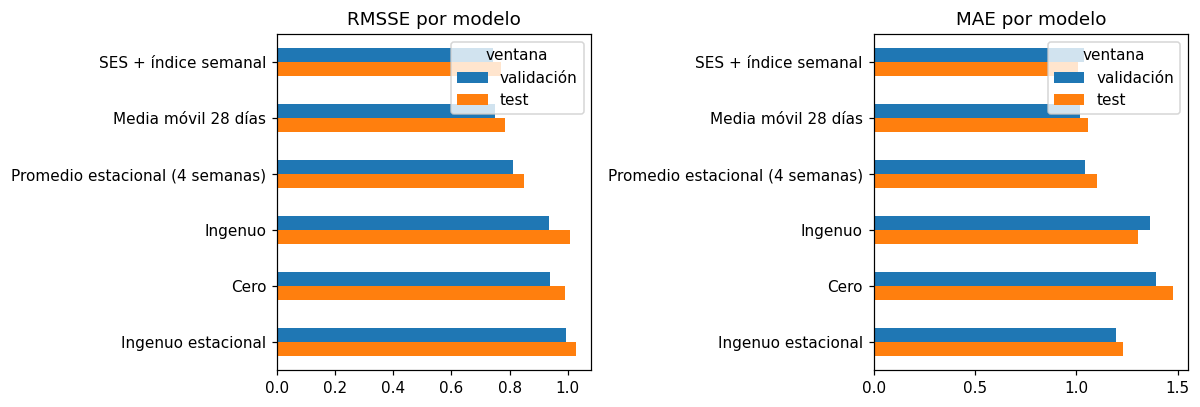

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, metrica in zip(axes, ["RMSSE", "MAE"]):
    tabla[metrica].plot.barh(ax=ax)
    ax.set_title(metrica + " por modelo")
    ax.set_ylabel("")
    ax.invert_yaxis()
plt.tight_layout()
plt.show()

### 3.1 RMSSE y MAE no siempre ordenan igual

El MAE se minimiza pronosticando la **mediana** de cada serie (que en muchas series esporádicas es cero), mientras que el RMSSE, basado en errores al cuadrado, se minimiza pronosticando el **promedio**. Por eso las dos métricas pueden ordenar los modelos de manera distinta. El modelo "Cero", inútil para planificar, se incluye para comprobarlo: la tabla lo compara con dos modelos de referencia.

In [7]:
r = resultados[resultados["modelo"].isin(["Cero", "Promedio estacional (4 semanas)", "SES + índice semanal"])]
r.pivot(index="modelo", columns="ventana", values=["RMSSE", "MAE"]).round(3)

RMSSE               MAE           
ventana                           test validación   test validación
modelo                                                             
Cero                             0.990      0.940  1.477      1.392
Promedio estacional (4 semanas)  0.849      0.811  1.101      1.045
SES + índice semanal             0.769      0.742  1.008      1.036

### 3.2 ¿Hay menos días sin ventas en el período reciente?

El modelo "Cero" resultó poco competitivo en MAE. Una posible explicación es que las ventas crecen con el tiempo y, por eso, hay menos días sin ventas en el período reciente que en la historia de cada serie. Se compara la proporción de días sin ventas (contada desde la primera venta de cada serie) con la de los últimos 56 días, y se mide qué proporción de series tiene mediana cero en esos 56 días: el MAE se minimiza pronosticando la mediana, por lo que "Cero" solo sería óptimo en las series con mediana cero. Es una descripción de la muestra y no se usa para ajustar ningún modelo.

In [8]:
inicio = (Y > 0).argmax(axis=1)
ceros_historia = np.mean([(Y[i, inicio[i]:] == 0).mean() for i in range(len(Y))])
ceros_reciente = (Y[:, -56:] == 0).mean()
mediana_cero = (np.median(Y[:, -56:], axis=1) == 0).mean()

print(f"Proporción de días sin ventas (desde la primera venta): {ceros_historia:.3f} | últimos 56 días: {ceros_reciente:.3f}")
print(f"Series con mediana cero en los últimos 56 días: {mediana_cero:.1%}")

Proporción de días sin ventas (desde la primera venta): 0.615 | últimos 56 días: 0.556
Series con mediana cero en los últimos 56 días: 60.0%


## 4. Resultados según el tipo de demanda

Las series se clasifican (suave, errática, intermitente, irregular) usando **solo el historial anterior al origen**, para no filtrar información del futuro. Se muestran los resultados de la ventana de validación: promedios simples dentro de cada tipo.

In [9]:
def desglose(ventana):
    tipo = clasificar_demanda(entrenamiento[ventana])["tipo"].to_numpy()
    filas = []
    for m in MODELOS:
        r_ = rmsse(entrenamiento[ventana], real[ventana], preds[(m, ventana)])
        a_ = np.abs(real[ventana] - preds[(m, ventana)]).mean(axis=1)
        g = pd.DataFrame({"tipo": tipo, "RMSSE": r_, "MAE": a_}).groupby("tipo").agg(
            RMSSE=("RMSSE", "mean"), MAE=("MAE", "mean"), series=("MAE", "size"))
        g["modelo"] = m
        filas.append(g.reset_index())
    return pd.concat(filas, ignore_index=True)

d_val = desglose("validación")
print("Series por tipo (validación):", d_val.groupby("tipo")["series"].first().to_dict())
print()
print("RMSSE por tipo de demanda:")
d_val.pivot(index="modelo", columns="tipo", values="RMSSE").round(3)

Series por tipo (validación): {'errática': 19, 'intermitente': 434, 'irregular': 121, 'suave': 26}

RMSSE por tipo de demanda:


tipo,errática,intermitente,irregular,suave
modelo,,,,
Cero,1.615,0.910,0.891,1.167
Ingenuo,1.235,0.943,0.871,0.912
Ingenuo estacional,1.072,1.016,0.932,0.873
Media móvil 28 días,0.912,0.765,0.688,0.689
Promedio estacional (4 semanas),0.965,0.828,0.746,0.722
SES + índice semanal,0.877,0.756,0.686,0.668


In [10]:
print("MAE por tipo de demanda:")
d_val.pivot(index="modelo", columns="tipo", values="MAE").round(3)

MAE por tipo de demanda:


tipo,errática,intermitente,irregular,suave
modelo,,,,
Cero,8.771,0.846,1.698,3.691
Ingenuo,5.778,0.953,1.790,2.946
Ingenuo estacional,4.658,0.824,1.672,2.647
Media móvil 28 días,4.011,0.726,1.363,2.142
Promedio estacional (4 semanas),4.104,0.733,1.427,2.254
SES + índice semanal,4.031,0.742,1.383,2.133


## 5. El modelo estadístico por dentro

**Índice semanal por categoría**, estimado en el origen del test. Un valor de 1,2 significa que ese día se vende un 20 % más que el promedio.

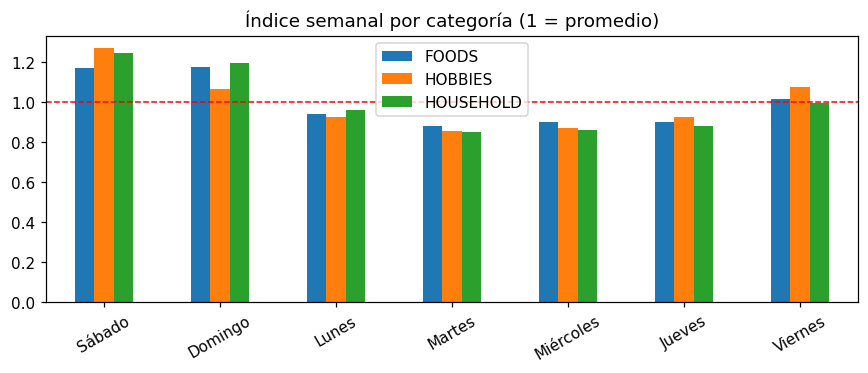

Alpha elegido por serie (origen del test):


,series
0.02,344
0.05,122
0.10,73
0.20,46
0.40,15


In [11]:
dias_semana = ["Sábado", "Domingo", "Lunes", "Martes", "Miércoles", "Jueves", "Viernes"]
_, info = ses_semanal(entrenamiento["test"], H, ctxs["test"]["wday_train"], ctxs["test"]["wday_futuro"], categorias)

indices = pd.DataFrame(info["indices"], index=dias_semana)
ax = indices.plot.bar(figsize=(8, 3.5), rot=30)
ax.axhline(1, color="red", linestyle="--", linewidth=1)
ax.set_title("Índice semanal por categoría (1 = promedio)")
plt.tight_layout()
plt.show()

print("Alpha elegido por serie (origen del test):")
pd.Series(info["alphas"]).value_counts().sort_index().to_frame("series")

## 6. Ejemplos de pronósticos

Una serie suave y una intermitente de la ventana de validación: los últimos 70 días de historia, las ventas reales de los 28 días siguientes y los pronósticos de dos modelos.

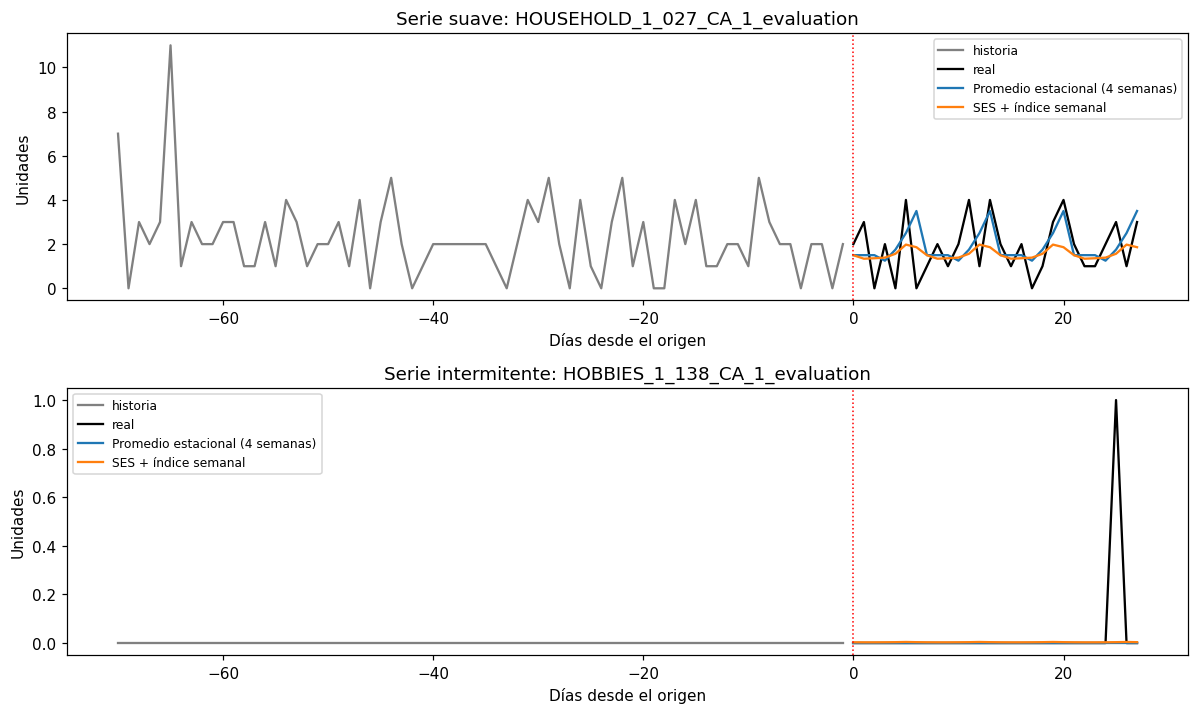

In [12]:
v = "validación"
tipo_val = clasificar_demanda(entrenamiento[v])["tipo"].to_numpy()
ejemplos = {t: int(np.where(tipo_val == t)[0][0]) for t in ["suave", "intermitente"] if (tipo_val == t).any()}

fig, axes = plt.subplots(len(ejemplos), 1, figsize=(11, 3.3 * len(ejemplos)), squeeze=False)
for ax, (t, i) in zip(axes.ravel(), ejemplos.items()):
    ax.plot(np.arange(-70, 0), entrenamiento[v][i, -70:], color="gray", label="historia")
    ax.plot(np.arange(0, H), real[v][i], color="black", label="real")
    for m in ["Promedio estacional (4 semanas)", "SES + índice semanal"]:
        ax.plot(np.arange(0, H), preds[(m, v)][i], label=m)
    ax.axvline(0, color="red", linestyle=":", linewidth=1)
    ax.set_title(f"Serie {t}: {muestra['id'].iloc[i]}")
    ax.set_xlabel("Días desde el origen")
    ax.set_ylabel("Unidades")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 7. Guardar resultados

In [13]:
ruta = os.path.join(ROOT, "reports", "resultados_modelos.csv")
acumulado = guardar_resultados(resultados, ruta)
print("Resultados guardados en", ruta, "|", len(acumulado), "filas")

Resultados guardados en c:\Users\Carlos\Desktop\Python-Prep\proyecto_forecasting_walmart\reports\resultados_modelos.csv | 12 filas


## 8. Conclusiones

- **Ventanas:** la validación (28 de marzo al 24 de abril de 2016) no tiene eventos; el test (25 de abril al 22 de mayo) tiene cuatro: Pesach End, Pascua ortodoxa, Cinco de Mayo y el Día de la Madre. Las 600 series tienen ventas anteriores a los dos orígenes, por lo que todas entran en el cálculo del RMSSE.
- **Mejor modelo:** SES + índice semanal tiene el menor RMSSE en las dos ventanas (0,742 en validación y 0,769 en test). Le sigue de cerca la media móvil de 28 días (0,751 y 0,782): la diferencia es de 1 a 2 % y se mide con una sola ventana por etapa, sin intervalo de confianza, por lo que no es concluyente. En MAE, la media móvil gana en validación (1,020 contra 1,036) y SES en test (1,008 contra 1,059).
- **Los modelos que repiten valores de días concretos rinden peor:** el ingenuo estacional (RMSSE 0,995 y 1,029) y el promedio estacional de 4 semanas (0,811 y 0,849) quedan por detrás de la media móvil. Con series tan esporádicas, lo vendido en un día concreto es muy ruidoso. El índice semanal compartido por categoría de SES recupera el patrón semanal sin ese ruido (0,742 contra 0,811 en validación).
- **Un RMSSE menor a 1 no es un buen resultado en sí mismo:** incluso pronosticar siempre cero da 0,940 y 0,990. Los valores sirven para comparar modelos entre sí, no contra el umbral de 1.
- **MAE y RMSSE no siempre ordenan igual:** el ingenuo estacional supera a "Cero" en MAE (1,195 contra 1,392 en validación; 1,233 contra 1,477 en test) pero pierde en RMSSE (0,995 contra 0,940; 1,029 contra 0,990). En cambio, "Cero" es el peor modelo en MAE en las dos ventanas: pronosticar cero no resulta competitivo en esta muestra.
- **Por tipo de demanda (validación; 19 series erráticas, 434 intermitentes, 121 irregulares y 26 suaves):** SES tiene el menor RMSSE en los cuatro tipos (errática 0,877, intermitente 0,756, irregular 0,686 y suave 0,668), aunque la ventaja sobre la media móvil es de 0,3 a 4 %. En MAE, la media móvil es mejor en errática, intermitente e irregular (4,011, 0,726 y 1,363) y SES solo en suave (2,133). Las series erráticas y suaves, que son pocas, tienen los errores en unidades más altos (4,0 y 2,1 contra 0,7 en las intermitentes), por lo que pesan mucho en el MAE global.
- **El modelo estadístico por dentro:** 344 de las 600 series (57 %) eligen el alpha más bajo de la grilla (0,02) y solo 15 eligen el más alto (0,4). El nivel de la mayoría de las series se mueve muy lentamente y el extremo inferior de la grilla puede estar limitando; no se amplió la grilla para no ajustar el modelo mirando la ventana de test.
- **Índice semanal por categoría:** tiene la misma forma en las tres categorías: sábado y domingo son los días más altos, y en cada día las tres categorías tienen valores similares, salvo el domingo, donde HOBBIES es alrededor de 10 % más bajo (valor leído del gráfico).
- **Días sin ventas en el tiempo:** la proporción de días sin ventas fue 0,615 en toda la historia (desde la primera venta de cada serie) y 0,556 en los últimos 56 días, una diferencia moderada de unos 6 puntos que puede reflejar el crecimiento de las ventas o que los primeros meses de cada serie nueva son más esporádicos. El 60 % de las series tiene mediana cero en esos 56 días, es decir que cero es la mediana de la mayoría de las series; aun así, "Cero" es el peor modelo en MAE. Por lo tanto, la explicación no es que la mayoría de las series tenga una mediana distinta de cero. Las tablas por tipo apuntan a otras causas: (1) las 45 series erráticas y suaves (7,5 % de la muestra) explican alrededor del 31 % del error absoluto de "Cero" en validación (cálculo hecho a partir de las tablas por tipo, ponderando por la cantidad de series de cada tipo); y (2) incluso entre las 434 series intermitentes, "Cero" tiene un MAE mayor (0,846) que la media móvil (0,726). Esto sugiere, como hipótesis sin verificar, que las ventas de esas series se agrupan en períodos, por lo que un nivel que sigue lo reciente le gana a un valor fijo en cero.
- **Referencia para los modelos siguientes:** SES + índice semanal, con RMSSE de 0,742 (validación) y 0,769 (test) y MAE de 1,036 y 1,008. LightGBM y la red neuronal tendrán que superar estos valores.
- **Limitaciones:** una sola ventana por etapa y sin intervalos de confianza; 600 series elegidas al azar entre las 30.490; modelos que no usan eventos, SNAP ni precios; y una ventana de validación sin eventos y un test con eventos de poco impacto, ambas sin los feriados más fuertes.